# Roman: load the trained model and evaluate it

Companion to `roman.ipynb`. This notebook loads a classifier saved by `roman.ipynb`, preprocesses a set of Roman cutouts the same way, predicts lens probabilities, and writes them to a CSV.

The evaluation dataset has the same structure as the training set (`cutouts.npz` plus `index.ecsv`) but uses a different random seed. Because it carries `is_lens` labels, the second half of the notebook characterizes the classifier's performance on it.

In [1]:
import os
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from scipy.special import expit
import keras
import tensorflow as tf
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, confusion_matrix
)
from pprint import pprint

print("Number of available GPUs: ", len(tf.config.list_physical_devices('GPU')))

gpus = tf.config.list_physical_devices('GPU')
if not gpus:
    print("No GPUs found.")
else:
    try:
        tf.config.set_visible_devices([gpus[0]], 'GPU')  # make only GPU 0 visible
        tf.config.experimental.set_memory_growth(gpus[0], True)
        print("Using GPU 0.")
    except Exception as e:
        print("Failed to set visible GPU:", e)

print("Visible GPUs:", tf.config.list_physical_devices('GPU'))

2026-11-09 17:15:44.140020: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 17:15:44.189874: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 17:15:45.840124: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Number of available GPUs:  2
Using GPU 0.
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1794266146.983067 3935906 gpu_device.cc:2411] Ignoring visible gpu device (device: 2, name: NVIDIA T400 4GB, pci bus id: 0000:e3:00.0, compute capability: 7.5) with core count: 6. The minimum required count is 8. You can adjust this requirement with the env var TF_MIN_GPU_MULTIPROCESSOR_COUNT.


Set the model and dataset paths. `threshold` is the probability above which a cutout counts as a lens. A value of 0.5 matches the `threshold=0.0` logit accuracy used during training.

In [2]:
model_path = Path('data') / 'models' / 'roman_v1.keras'

# evaluation dataset: same structure as the training set, different seed
cutouts_dir = Path('/data/bwedig/mejiro/lens_search/cutouts_test/wfi01_93px')

# the set roman.ipynb trained on, used only to warn against evaluating on it
training_cutouts_dir = Path('/data/bwedig/mejiro/lens_search/cutouts/wfi01_93px')

threshold = 0.5
batch_size = 256

model_name = model_path.stem
dataset_name = cutouts_dir.name
predictions_path = Path('data') / 'predictions' / f'{model_name}_{dataset_name}.csv'
figure_dir = Path('figures') / f'{model_name}_{dataset_name}'
figure_dir.mkdir(parents=True, exist_ok=True)

if cutouts_dir.resolve() == training_cutouts_dir.resolve():
    print('WARNING: cutouts_dir is the training set, so the metrics below are optimistic.')

# colors follow the class everywhere: lenses blue, non-lenses orange
lens_color = '#2a78d6'
nonlens_color = '#eb6834'
reference_color = '0.5'
precision_color = '#1baf7a'
recall_color = '#6250d6'


def save(fig, name):
    path = figure_dir / f'{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Saved {path}')

## Load and preprocess the cutouts

`load_cutouts` in `roman_cutouts.py` applies the same preprocessing as `roman.ipynb`: it drops partial cutouts at the detector edge (they contain NaN pixels), then scales each band to [0, 1] and gamma-corrects it to a median of 0.2.

In [3]:
from roman_cutouts import load_cutouts

index, data, bands = load_cutouts(cutouts_dir)
assert 'is_lens' in index.colnames, 'this notebook needs a labeled dataset'
is_lens = np.array(index['is_lens'])
y_true = is_lens.astype(int)

print(f'bands: {bands}')
print(f'lenses: {data[is_lens].shape}')
print(f'nonlenses: {data[~is_lens].shape}')

Reading from /data/bwedig/mejiro/lens_search/cutouts_test/wfi01_93px...
dropped 460 partial cutouts
bands: ['F106' 'F129' 'F158']
lenses: (104, 93, 93, 3)
nonlenses: (10340, 93, 93, 3)


Load the saved model

In [4]:
print(f'Loading {model_path}...')
model = keras.models.load_model(model_path)
assert model.input_shape[1:] == data.shape[1:], f'model expects {model.input_shape[1:]}, data is {data.shape[1:]}'

Loading data/models/roman_v1.keras...


I0000 00:00:1794266156.981784 3935906 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8240 MB memory:  -> device: 0, name: NVIDIA RTX 6000 Ada Generation, pci bus id: 0000:31:00.0, compute capability: 8.9


## Predict

The model outputs logits, so a sigmoid converts them to probabilities. The sigmoid runs in float64 so that confident scores do not round to exactly 0 or 1.

In [5]:
logits = model.predict(data, batch_size=batch_size, verbose=1).ravel()
probs = expit(logits.astype(np.float64))
y_pred = (probs > threshold).astype(int)

2026-11-09 17:15:59.502036: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fa19c004fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-09 17:15:59.502057: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 6000 Ada Generation, Compute Capability 8.9
2026-11-09 17:15:59.513671: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-09 17:15:59.604221: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91301
2026-11-09 17:16:02.886387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:16:03.030437: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel time

39/41 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step

2026-11-09 17:16:15.006054: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:16:15.137679: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:16:19.867586: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:16:19.953293: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:16:20.043127: E external/local_xla/xla/stream_

41/41 ━━━━━━━━━━━━━━━━━━━━ 23s 304ms/step


Write one row per scored cutout. Partial cutouts are not scored, so they are absent from the CSV.

In [6]:
predictions = Table({
    'object_id': index['object_id'],
    'is_lens': is_lens,
    'preds': y_pred,
    'probs': probs,
})
predictions_path.parent.mkdir(parents=True, exist_ok=True)
predictions.write(predictions_path, format='ascii.csv', overwrite=True)
print(f'Wrote {len(predictions)} rows to {predictions_path}')
predictions[:5]

Wrote 10444 rows to data/predictions/roman_v1_wfi01_93px.csv


object_id,is_lens,preds,probs
str11,bool,int64,float64
wfi01_00002,False,0,0.0003965963757637691
wfi01_00005,False,0,0.0003565971676701962
wfi01_00007,True,1,0.9584588288247282
wfi01_00008,False,0,4.5133085723208774e-05
wfi01_00010,False,0,3.8220545954103544e-05


## Performance

Summary metrics at the chosen threshold. ROC AUC and average precision (the area under the precision-recall curve) do not depend on the threshold.

In [7]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()


def ratio(numerator, denominator):
    return numerator / denominator if denominator else float('nan')


metrics = {
    'n_lenses': int(tp + fn),
    'n_nonlenses': int(tn + fp),
    'threshold': threshold,
    'accuracy': ratio(tp + tn, tp + tn + fp + fn),
    'precision (purity)': ratio(tp, tp + fp),
    'recall (completeness)': ratio(tp, tp + fn),
    'false positive rate': ratio(fp, fp + tn),
    'F1': ratio(2 * tp, 2 * tp + fp + fn),
    'ROC AUC': roc_auc_score(y_true, probs),
    'average precision': average_precision_score(y_true, probs),
}
pprint(metrics, sort_dicts=False)

{'n_lenses': 104,
 'n_nonlenses': 10340,
 'threshold': 0.5,
 'accuracy': np.float64(0.9687859057832248),
 'precision (purity)': np.float64(0.23696682464454977),
 'recall (completeness)': np.float64(0.9615384615384616),
 'false positive rate': np.float64(0.031141199226305608),
 'F1': np.float64(0.38022813688212925),
 'ROC AUC': 0.9888655891980359,
 'average precision': 0.6895836554788166}


Confusion matrix. Cell shading is the fraction of each true class, so it stays readable when the classes are unbalanced.

Saved figures/roman_v1_wfi01_93px/confusion_matrix.png


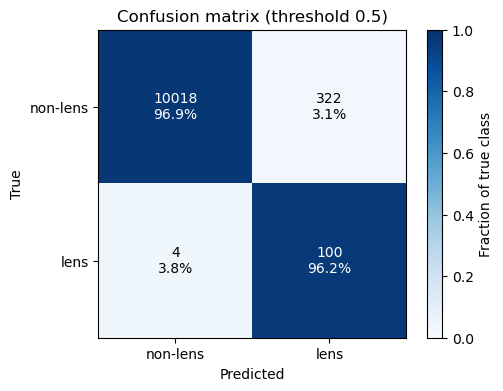

In [8]:
cm = np.array([[tn, fp], [fn, tp]])
cm_fraction = cm / cm.sum(axis=1, keepdims=True)
class_names = ['non-lens', 'lens']

fig, ax = plt.subplots(figsize=(5, 3.8), constrained_layout=True)
im = ax.imshow(cm_fraction, cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n{cm_fraction[i, j]:.1%}', ha='center', va='center',
                color='white' if cm_fraction[i, j] > 0.5 else 'black')
ax.set_xticks([0, 1], class_names)
ax.set_yticks([0, 1], class_names)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion matrix (threshold {threshold})')
fig.colorbar(im, ax=ax, label='Fraction of true class')
save(fig, 'confusion_matrix')
plt.show()

ROC and precision-recall curves, computed from the continuous probabilities. The dot marks the operating point at `threshold`. On the precision-recall curve, the dashed line is the precision of random guessing, which equals the lens fraction.

Saved figures/roman_v1_wfi01_93px/roc_precision_recall.png


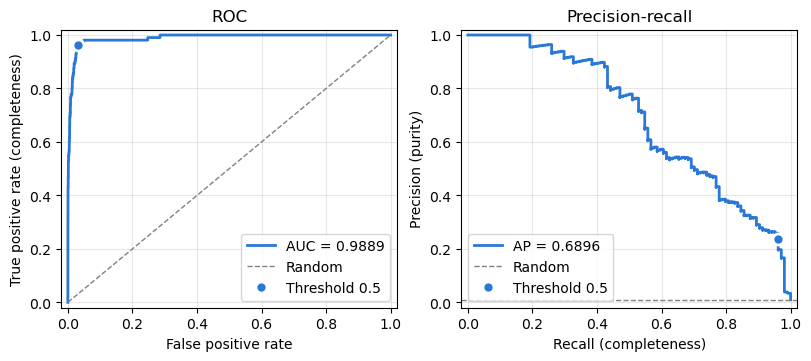

In [9]:
fpr, tpr, _ = roc_curve(y_true, probs)
precision, recall, _ = precision_recall_curve(y_true, probs)

fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True)

ax[0].plot(fpr, tpr, color=lens_color, lw=2, label=f'AUC = {metrics["ROC AUC"]:.4f}')
ax[0].plot([0, 1], [0, 1], color=reference_color, lw=1, ls='--', label='Random')
ax[0].plot(metrics['false positive rate'], metrics['recall (completeness)'], 'o', ms=8,
           color=lens_color, mec='white', mew=2, label=f'Threshold {threshold}')
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate (completeness)')
ax[0].set_title('ROC')
ax[0].legend(loc='lower right')

ax[1].step(recall, precision, where='post', color=lens_color, lw=2,
           label=f'AP = {metrics["average precision"]:.4f}')
ax[1].axhline(y_true.mean(), color=reference_color, lw=1, ls='--', label='Random')
ax[1].plot(metrics['recall (completeness)'], metrics['precision (purity)'], 'o', ms=8,
           color=lens_color, mec='white', mew=2, label=f'Threshold {threshold}')
ax[1].set_xlabel('Recall (completeness)')
ax[1].set_ylabel('Precision (purity)')
ax[1].set_title('Precision-recall')
ax[1].legend(loc='lower left')

for a in ax:
    a.set_xlim(-0.02, 1.02)
    a.set_ylim(-0.02, 1.02)
    a.grid(alpha=0.3)

save(fig, 'roc_precision_recall')
plt.show()

Score distributions and threshold choice. The probability axes use a logit scale, which spreads out the scores that crowd near 0 and 1. Overlap between the two histograms is where the classifier confuses the classes.

Saved figures/roman_v1_wfi01_93px/scores_and_thresholds.png


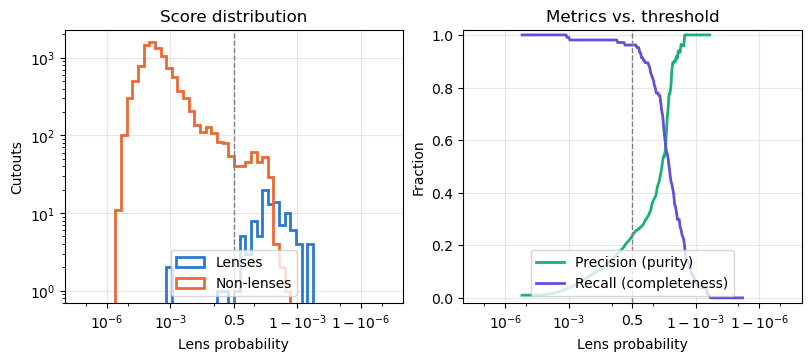

In [ ]:
clip = 1e-8
plot_probs = np.clip(probs, clip, 1 - clip)
edges = expit(np.linspace(-np.log(1 / clip - 1), np.log(1 / clip - 1), 61))
thresholds = expit(np.linspace(-12, 12, 241))
precision_at = np.array([ratio(np.sum(is_lens & (probs > t)), np.sum(probs > t)) for t in thresholds])
recall_at = np.array([np.mean(probs[is_lens] > t) for t in thresholds])

fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True)

ax[0].hist(plot_probs[is_lens], bins=edges, histtype='step', lw=2, color=lens_color, label='Lenses')
ax[0].hist(plot_probs[~is_lens], bins=edges, histtype='step', lw=2, color=nonlens_color, label='Non-lenses')
ax[0].set_yscale('log')
ax[0].set_ylabel('Cutouts')
ax[0].set_title('Score distribution')

ax[1].plot(thresholds, precision_at, color=precision_color, lw=2, label='Precision (purity)')
ax[1].plot(thresholds, recall_at, color=recall_color, lw=2, label='Recall (completeness)')
ax[1].set_ylim(-0.02, 1.02)
ax[1].set_ylabel('Fraction')
ax[1].set_title('Metrics vs. threshold')

logit_ticks = [1e-6, 1e-3, 0.5, 1 - 1e-3, 1 - 1e-6]
logit_labels = ['$10^{-6}$', '$10^{-3}$', '0.5', '$1-10^{-3}$', '$1-10^{-6}$']
for a in ax:
    a.set_xscale('logit')
    a.set_xlim(clip, 1 - clip)
    a.set_xticks(logit_ticks, logit_labels)
    a.xaxis.set_minor_formatter(plt.NullFormatter())
    a.axvline(threshold, color=reference_color, lw=1, ls='--')
    a.set_xlabel('Lens probability')
    a.legend(loc='lower center')
    a.grid(alpha=0.3)

save(fig, 'scores_and_thresholds')
plt.show()

### Where does the classifier fail?

Completeness against the lens properties in `index.ecsv`, in bins that each hold about the same number of lenses. Error bars are 68% Wilson intervals, which stay sensible when a bin holds few lenses or all of them are detected.

Saved figures/roman_v1_wfi01_93px/completeness_vs_lens_properties.png


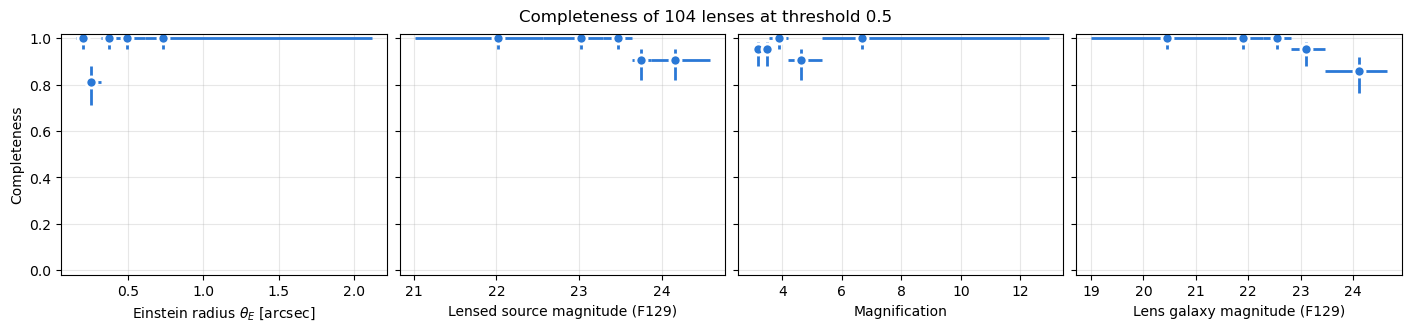

In [ ]:
def wilson_interval(k, n, z=1.0):
    """68% (z=1) Wilson score interval for a binomial fraction k/n."""
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return p, center - half, center + half


def binned_fraction(x, success, n_bins):
    """Fraction of `success` in quantile bins of x, skipping NaN values and empty bins."""
    finite = np.isfinite(x)
    x, success = x[finite], success[finite]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    which = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    rows = []
    for b in range(len(edges) - 1):
        in_bin = which == b
        n = in_bin.sum()
        if n == 0:
            continue
        p, lo, hi = wilson_interval(success[in_bin].sum(), n)
        rows.append((np.median(x[in_bin]), edges[b], edges[b + 1], p, lo, hi, n))
    return np.array(rows).reshape(-1, 7).T


def plot_binned(ax, x, success, n_bins, color):
    mid, left, right, p, lo, hi, n = binned_fraction(x, success, n_bins)
    # clip floating-point noise when every lens in a bin is detected (or none are)
    yerr = np.clip([p - lo, hi - p], 0, None)
    ax.errorbar(mid, p, xerr=[mid - left, right - mid], yerr=yerr,
                fmt='o', ms=8, color=color, mec='white', mew=2, lw=2, capsize=0)
    return n


detected = probs > threshold
lens_properties = [
    ('theta_E', r'Einstein radius $\theta_E$ [arcsec]'),
    ('lensed_source_mag_F129', 'Lensed source magnitude (F129)'),
    ('magnification', 'Magnification'),
    ('mag_F129', 'Lens galaxy magnitude (F129)'),
]
n_lens_bins = max(1, min(10, is_lens.sum() // 20))

fig, axes = plt.subplots(1, len(lens_properties), figsize=(14, 3.2), sharey=True, constrained_layout=True)
for ax, (column, label) in zip(axes, lens_properties):
    x = np.array(index[column][is_lens], dtype=float)
    plot_binned(ax, x, detected[is_lens], n_lens_bins, lens_color)
    ax.set_xlabel(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Completeness')
axes[0].set_ylim(-0.02, 1.02)
fig.suptitle(f'Completeness of {is_lens.sum()} lenses at threshold {threshold}')
save(fig, 'completeness_vs_lens_properties')
plt.show()

False positive rate against the magnitude of the non-lens galaxy. Bright, extended galaxies with arcs or neighbors are the usual contaminants.

Saved figures/roman_v1_wfi01_93px/false_positive_rate_vs_magnitude.png


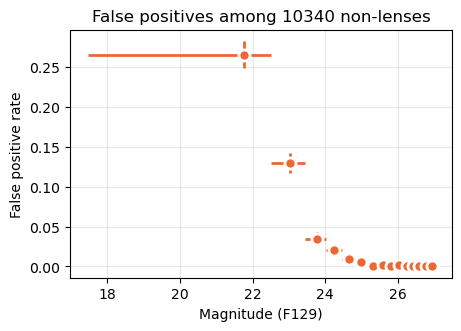

In [ ]:
n_nonlens_bins = max(1, min(15, (~is_lens).sum() // 50))

fig, ax = plt.subplots(figsize=(4.5, 3.2), constrained_layout=True)
x = np.array(index['mag_F129'][~is_lens], dtype=float)
plot_binned(ax, x, detected[~is_lens], n_nonlens_bins, nonlens_color)
ax.set_xlabel('Magnitude (F129)')
ax.set_ylabel('False positive rate')
ax.set_title(f'False positives among {(~is_lens).sum()} non-lenses')
ax.grid(alpha=0.3)
save(fig, 'false_positive_rate_vs_magnitude')
plt.show()

### Misclassified examples

The most confidently wrong cutouts: missed lenses with the lowest scores, and non-lenses with the highest. Images are RGB composites with F158 as red, F129 as green and F106 as blue.

Saved figures/roman_v1_wfi01_93px/false_negatives.png


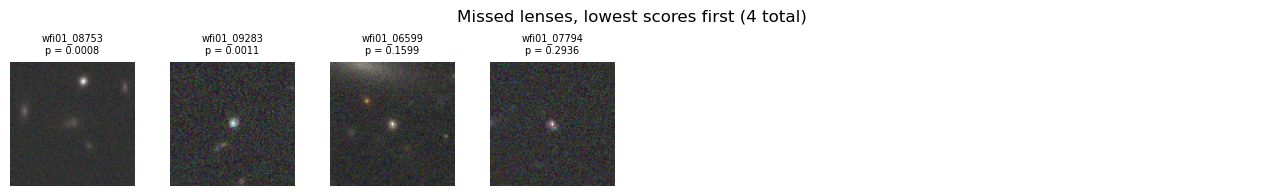

Saved figures/roman_v1_wfi01_93px/false_positives.png


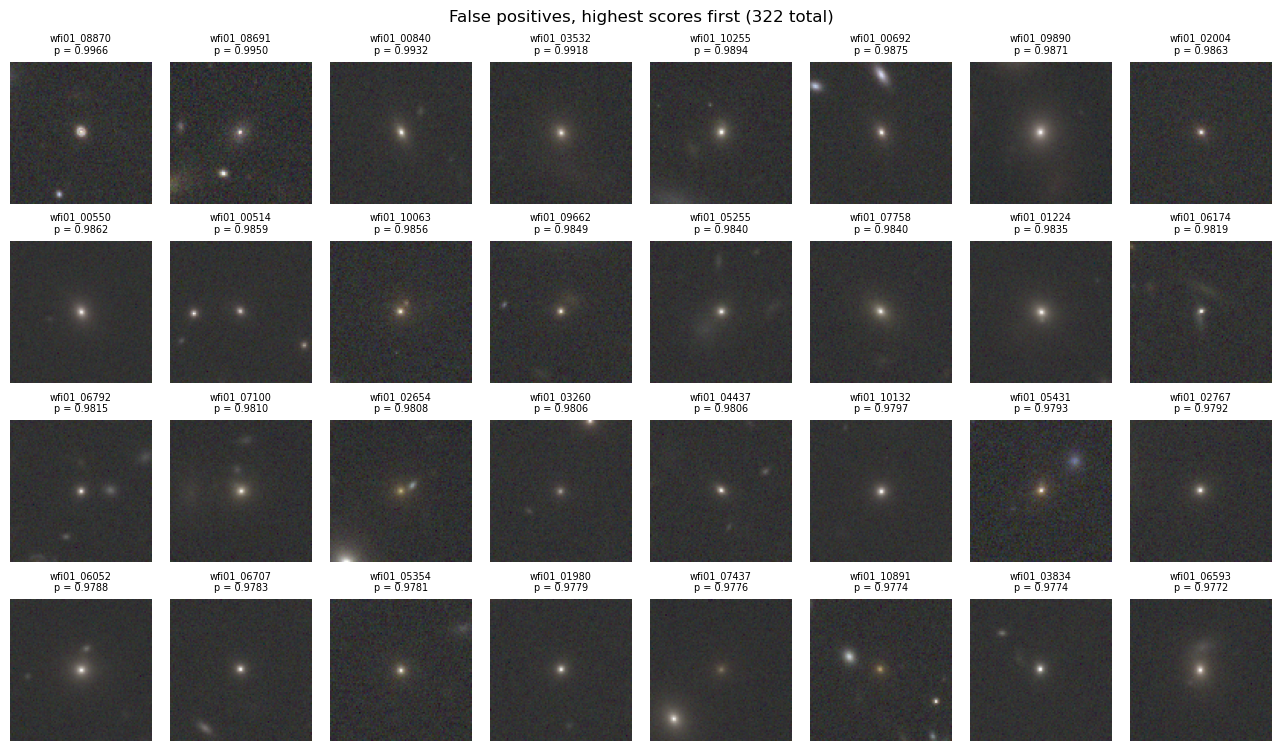

In [13]:
def show_grid(indices, title, n_cols=8, name=None):
    if len(indices) == 0:
        print(f'{title}: none')
        return
    n_rows = math.ceil(len(indices) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.6 * n_cols, 1.85 * n_rows),
                             squeeze=False, constrained_layout=True)
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, indices):
        ax.imshow(data[i][:, :, ::-1])  # bands are (F106, F129, F158), so reverse for RGB
        ax.set_title(f'{index["object_id"][i]}\np = {probs[i]:.4f}', fontsize=7)
    fig.suptitle(title)
    if name is not None:
        save(fig, name)
    plt.show()


n_show = 32
false_negatives = np.flatnonzero(is_lens & ~detected)
false_positives = np.flatnonzero(~is_lens & detected)
false_negatives = false_negatives[np.argsort(probs[false_negatives])][:n_show]
false_positives = false_positives[np.argsort(-probs[false_positives])][:n_show]

show_grid(false_negatives, f'Missed lenses, lowest scores first ({fn} total)', name='false_negatives')
show_grid(false_positives, f'False positives, highest scores first ({fp} total)', name='false_positives')

For comparison, a random sample of correctly classified cutouts from each class.

Saved figures/roman_v1_wfi01_93px/true_positives.png


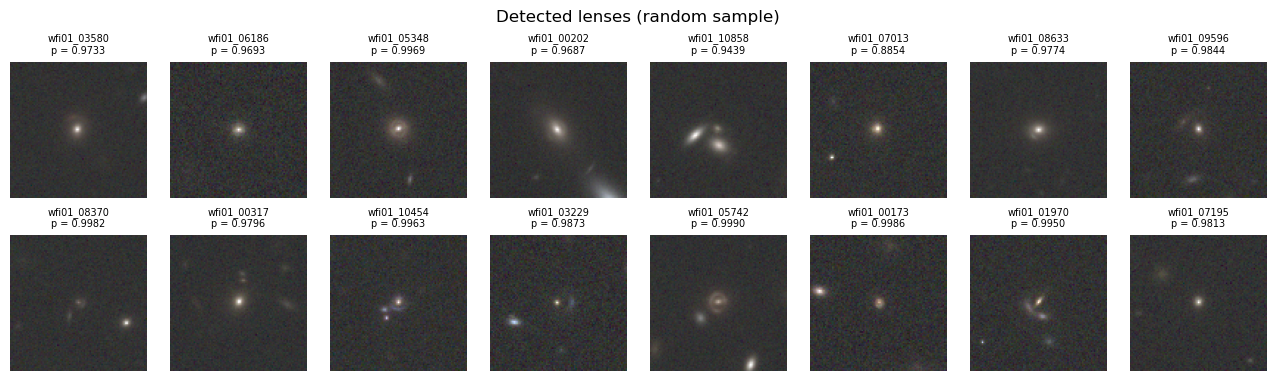

Saved figures/roman_v1_wfi01_93px/true_negatives.png


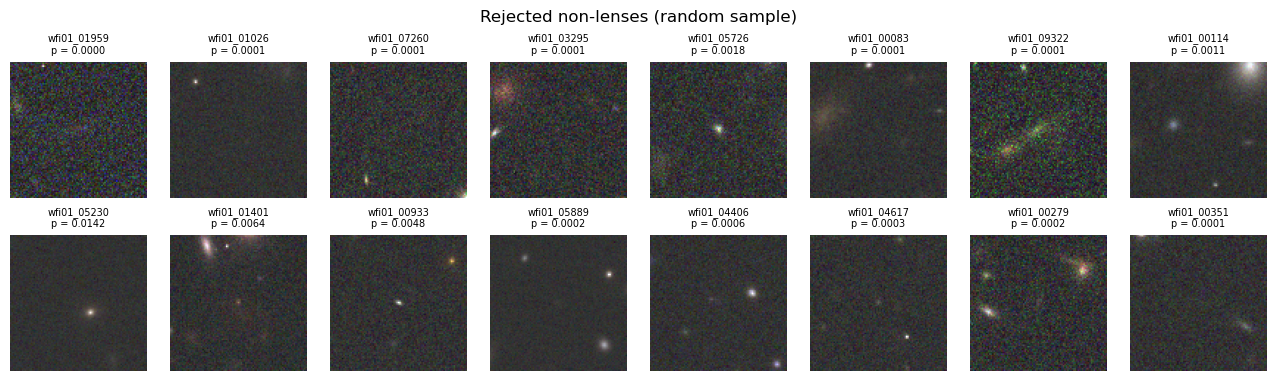

In [14]:
rng = np.random.default_rng(0)
true_positives = np.flatnonzero(is_lens & detected)
true_negatives = np.flatnonzero(~is_lens & ~detected)

show_grid(rng.choice(true_positives, min(16, len(true_positives)), replace=False),
          'Detected lenses (random sample)', name='true_positives')
show_grid(rng.choice(true_negatives, min(16, len(true_negatives)), replace=False),
          'Rejected non-lenses (random sample)', name='true_negatives')